# Patch leaving: does the search follow the marginal value theorem?

The earlier notebooks found that mice leave the end of the arena that holds the target on more than 40% of trials. This one looks at the leaving itself. Treat each end of the arena as a **patch**: is there a typical time a mouse persists in one before abandoning it for the other, and does that time behave the way the marginal value theorem (MVT) says a forager's should?

**What MVT says.** A forager should leave a patch when the rate of return from staying falls to the average rate it gets from the environment as a whole, travel included. Three things follow:

1. Returns from a patch must *diminish* with time in it, and the forager leaves at the point they have fallen to the long-run average.
2. It should stay longer in a *richer* patch.
3. It should stay a shorter time in a patch that is already *depleted*.

(The fourth classic prediction, longer stays when travel between patches is longer, cannot be tested: the two ends are separated by one row of cells and the crossing takes about 0.3 s.)

**What a patch yields here.** There is one reward per trial, so the yield is not reward but *information*. The search ends the moment the nose enters the target cell, so every cell entered without that happening is known to be empty. Each end has 12 target cells; a patch yields **newly checked cells**, and it is depleted when the mouse has been through all 12. On no-cue trials every unchecked cell is equally likely to be the target, so new cells per second is exactly the rate at which the mouse is closing in.

**Definitions** (`src/visits.py`).
- A **visit** to an end starts when the nose enters that end zone and ends when the mouse finds the target or visits the other end. Stepping into the middle row and coming back is part of the same visit.
- An entry counts only if the nose gets at least one cell deep. About 20% of raw zone entries are shallower than that - the mouse hovering at the middle row, where the ports are - and the depth distribution is clearly bimodal around that point.
- A visit that ends with a visit to the other end is a **switch**. Its **residence time** runs from entry to the last frame in the patch.
- A **give-up visit** is a visit to the end that does not hold the target. These always end in a switch, so their residence times are complete.

**Two restrictions, both to keep leaving from being confused with finding.** Visits already under way when the trial starts are left out of anything timed, because the mouse entered during the ITI. And trials with the target in the middle row are dropped: a mouse on its way out of a patch crosses the middle row, finds the target there, and its exit is never recorded. The same interception happens inside a patch that holds the target (the mouse runs into it while leaving), which is why visits to the target's end look longer than give-up visits and are never compared with them directly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from src import config as cfg
from src.trials import USECOLS, discover_sessions, load_trials
from src.visits import load_visits, PATCH_CELLS      # run `python -m src.visits` to rebuild output/visits*.csv
from src.stats import hazard, km_median

pd.set_option('display.width', 200, 'display.precision', 3)

SESSION_TYPES = ['x', 'v']
TYPE_COLOR = {'x': '#2a78d6', 'v': '#7a52c7'}
TYPE_LABEL = {'x': 'Odor', 'v': 'Vision'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

KEYS = ['experiment', 'mouse', 'session', 'trial']
PATCH_LEN = cfg.LOW_MAX_Y                        # px from the far wall to the middle row

t = pd.concat([load_trials(e).assign(experiment=e) for e in ('odor', 'vision')], ignore_index=True)
v = pd.concat([load_visits(e) for e in ('odor', 'vision')], ignore_index=True)
v = v.merge(t[KEYS + ['search_s']], on=KEYS).sort_values(KEYS + ['visit']).reset_index(drop=True)
v = v[(v.search_s <= cfg.MAX_SEARCH_S) & (v.target_zone != 'mid')]
v['timed'] = ~v.from_trial_start                 # the mouse entered during the search, so its clock is known
v['path_len'] = v.path_px / PATCH_LEN            # distance run during the visit, in patch lengths

## 1. Visits

Odor `x` sessions and vision `v` sessions, the same nine mice in both, each mouse's first ten sessions of each experiment.

In [2]:
per_trial = v.groupby(KEYS + ['session_type']).agg(visits=('visit', 'size'), switches=('switched', 'sum')).reset_index()
overview = pd.DataFrame({
    'mice': v.groupby('session_type').mouse.nunique(),
    'trials': per_trial.groupby('session_type').size(),
    'visits': v.groupby('session_type').size(),
    'switches per trial (mean)': per_trial.groupby('session_type').switches.mean(),
    'trials with no switch': per_trial.groupby('session_type').switches.apply(lambda s: (s == 0).mean()),
    'give-up visits, timed': v[v.timed & ~v.target_here].groupby('session_type').size(),
    'median travel (s)': v.groupby('session_type').travel_s.median(),
}).loc[SESSION_TYPES]
overview

,mice,trials,visits,switches per trial (mean),trials with no switch,"give-up visits, timed",median travel (s)
session_type,,,,,,,
x,9,10043,25582,1.547,0.290,6298,0.333
v,9,11532,28552,1.476,0.298,6783,0.268


What the searches look like: nose position along the long axis for ten trials of one session (the first ten after trial 20 with a search of at least 5 s). The grey band is the middle row; the colored bar at the right marks the target's row; ticks along the top mark each switch.

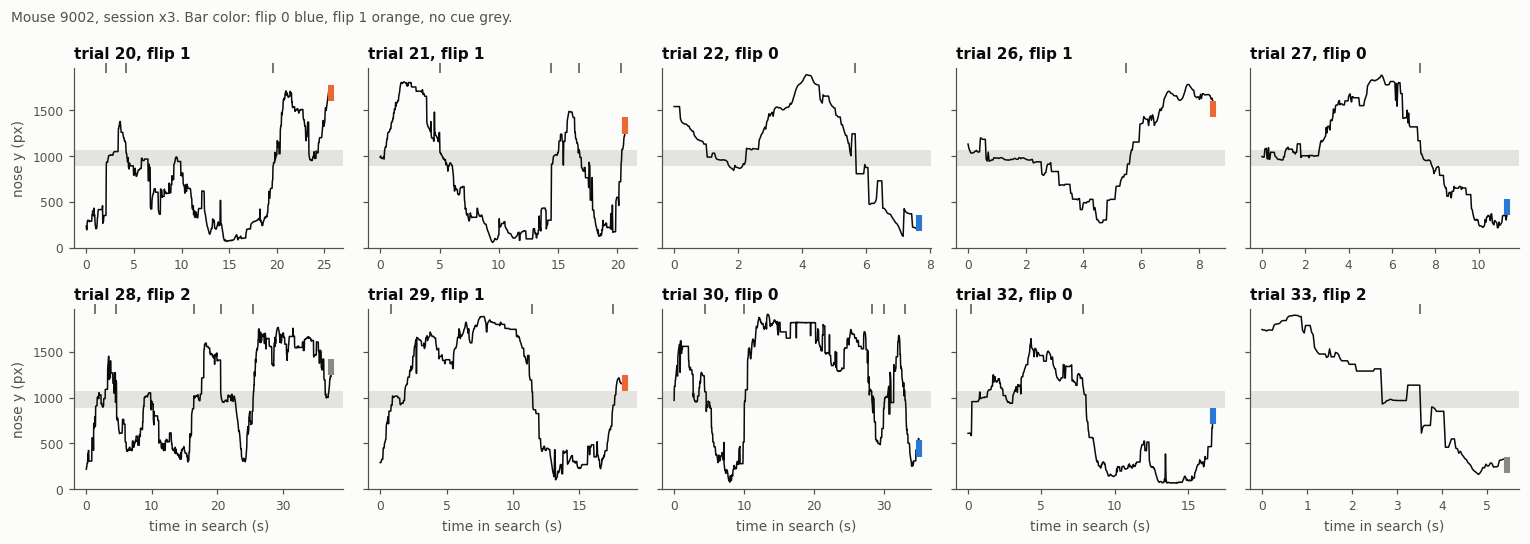

In [3]:
EXAMPLE = ('odor', '9002', 'x3')
FLIP_COLOR = {0: '#2a78d6', 1: '#eb6834', 2: '#8a8985'}

path = next(s['path'] for s in discover_sessions(EXAMPLE[0]) if (s['mouse'], s['session']) == EXAMPLE[1:])
ev = pd.read_csv(path, usecols=USECOLS)
ex = v[(v.experiment == EXAMPLE[0]) & (v.mouse == EXAMPLE[1]) & (v.session == EXAMPLE[2])]
shown = sorted(ex[(ex.trial >= 20) & (ex.search_s >= 5)].trial.unique())[:10]

fig, axes = plt.subplots(2, 5, figsize=(14, 5), sharey=True)
for ax, tr in zip(axes.flat, shown):
    d, vis = ev[ev.trial_number == tr], ex[ex.trial == tr]
    d = d.iloc[:int(np.flatnonzero(d.target_cell.isna())[0]) + 1]
    sec = (d.bonsai_ts - d.bonsai_ts.iloc[0]) / 1000
    flip, target_row = int(vis.flip.iloc[0]), vis.target_cell.iloc[0] // cfg.INNER_COLS + 1
    ax.axhspan(cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y, color=GRID, lw=0)
    ax.plot(sec, d[f'{cfg.POS}_y'], color=INK, lw=1)
    ax.plot([sec.iloc[-1]] * 2, [target_row * cfg.CELL_H, (target_row + 1) * cfg.CELL_H], color=FLIP_COLOR[flip], lw=4, solid_capstyle='butt')
    switch_s = (vis.enter_s + vis.residence_s)[vis.switched]
    ax.plot(switch_s, np.full(len(switch_s), cfg.FRAME_H), '|', color=MUTED, ms=7, clip_on=False)
    ax.set(ylim=(0, cfg.FRAME_H), title=f"trial {tr}, flip {flip}")
for ax in axes[-1]:
    ax.set_xlabel('time in search (s)')
for ax in axes[:, 0]:
    ax.set_ylabel('nose y (px)')
fig.suptitle(f"Mouse {EXAMPLE[1]}, session {EXAMPLE[2]}. Bar color: flip 0 blue, flip 1 orange, no cue grey.", x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

## 2. Is there a typical persistence period?

Give-up visits on no-cue trials: the mouse is in the end that does not hold the target, nothing tells it so, and it leaves when it chooses to.

The question is the shape of the **leaving hazard** - the chance per second of leaving, given the mouse is still there. If leaving were unrelated to how long the mouse had been in the patch, the hazard would be flat and residence times exponential. A typical persistence period shows up as a hazard that starts at zero and rises to a peak.

In [4]:
give_up = v[v.timed & ~v.target_here & ~v.cue]
T_EDGES = np.arange(0, 20.01, 0.5)
L_EDGES = np.arange(0, 8.01, 0.25)
centers = lambda edges: (edges[:-1] + edges[1:]) / 2

def mouse_curves(d, f):
    """One curve per mouse (rows), from f(that mouse's visits)."""
    return pd.DataFrame({m: f(g) for m, g in d.groupby('mouse')}).T

def band(ax, x, curves, color, label=None, ls='-'):
    """Mean across mice with a +-1 SEM band."""
    mean, sem = curves.mean(), curves.sem()
    ax.fill_between(x, mean - sem, mean + sem, color=color, alpha=0.18, lw=0)
    ax.plot(x, mean, color=color, lw=2, ls=ls, label=label)

rows = {}
for st in SESSION_TYPES:
    d = give_up[give_up.session_type == st]
    h = hazard(d.residence_s, d.switched, T_EDGES)[T_EDGES[:-1] < 10]      # look for the peak in the first 10 s
    late = hazard(d.residence_s, d.switched, np.array([10., 20.]))[0]
    med = d.groupby('mouse').residence_s.median()
    rows[st] = {'visits': len(d), 'median (s)': d.residence_s.median(), 'q25': d.residence_s.quantile(0.25), 'q75': d.residence_s.quantile(0.75),
                'mouse medians, min': med.min(), 'max': med.max(),
                'hazard peak at (s)': centers(T_EDGES)[np.nanargmax(h)], 'peak hazard (/s)': np.nanmax(h), 'hazard 10-20 s (/s)': late,
                'left within 1 s': (d.residence_s < 1).mean(), 'stayed over 10 s': (d.residence_s > 10).mean(),
                'reached far half': (d.max_depth_px >= 2 * cfg.CELL_H).mean(), 'reached last row': (d.max_depth_px >= 3 * cfg.CELL_H).mean(),
                'median path (patch lengths)': d.path_len.median(), 'left before 1.5 lengths': (d.path_len < 1.5).mean(),
                'cells checked, fresh patch (median)': d[d.cells_before == 0].cells_new.median(),
                'fresh patch, all 12 checked': (d[d.cells_before == 0].cells_new == PATCH_CELLS).mean()}
persistence = pd.DataFrame(rows).T
persistence

,visits,median (s),q25,q75,"mouse medians, min",max,hazard peak at (s),peak hazard (/s),hazard 10-20 s (/s),left within 1 s,stayed over 10 s,reached far half,reached last row,median path (patch lengths),left before 1.5 lengths,"cells checked, fresh patch (median)","fresh patch, all 12 checked"
x,2131.0,4.633,2.933,8.549,3.402,5.601,3.25,0.253,0.11,0.007,0.206,0.957,0.826,2.771,0.107,8.0,0.053
v,2046.0,3.949,2.568,6.937,2.535,5.635,3.25,0.320,0.13,0.016,0.157,0.958,0.845,2.516,0.118,9.0,0.056


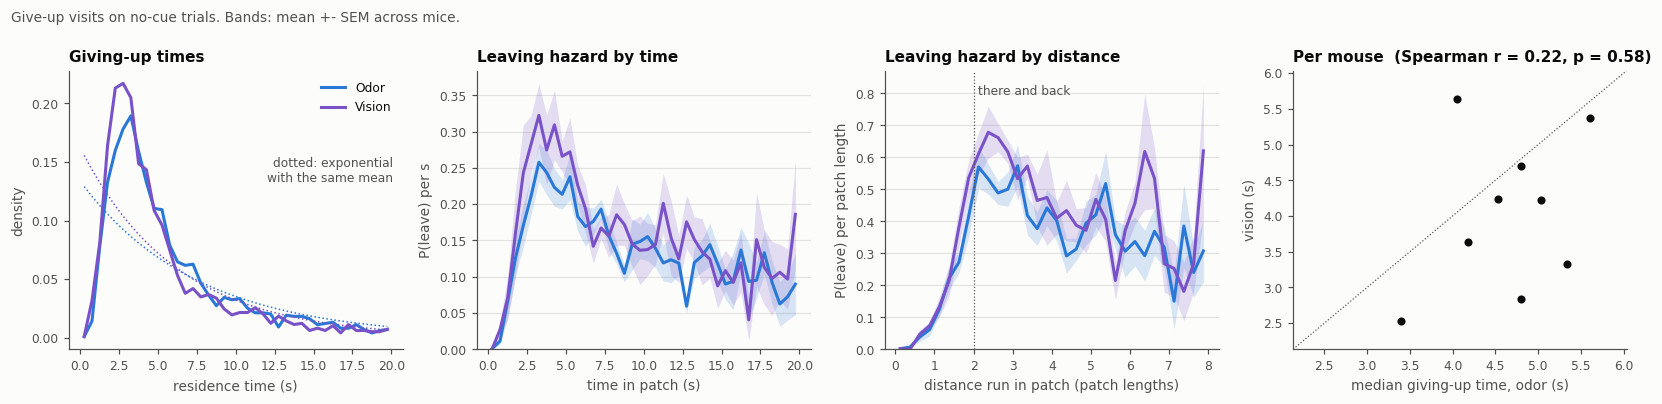

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7))
ax = axes[0]
for st in SESSION_TYPES:
    d = give_up[give_up.session_type == st]
    density, _ = np.histogram(d.residence_s, bins=T_EDGES, density=True)
    ax.plot(centers(T_EDGES), density, color=TYPE_COLOR[st], lw=2, label=TYPE_LABEL[st])
    ax.plot(centers(T_EDGES), sps.expon(scale=d.residence_s.mean()).pdf(centers(T_EDGES)), color=TYPE_COLOR[st], lw=1, ls=':')
ax.set(xlabel='residence time (s)', ylabel='density', title='Giving-up times')
ax.text(0.97, 0.6, 'dotted: exponential\nwith the same mean', transform=ax.transAxes, ha='right', fontsize=8, color=MUTED)
ax.legend()

for ax, col, edges, xlabel, title in ((axes[1], 'residence_s', T_EDGES, 'time in patch (s)', 'Leaving hazard by time'),
                                      (axes[2], 'path_len', L_EDGES, 'distance run in patch (patch lengths)', 'Leaving hazard by distance')):
    for st in SESSION_TYPES:
        d = give_up[give_up.session_type == st]
        band(ax, centers(edges), mouse_curves(d, lambda g: hazard(g[col], g.switched, edges)), TYPE_COLOR[st])
    ax.set(xlabel=xlabel, ylabel='P(leave) per ' + ('s' if col == 'residence_s' else 'patch length'), title=title, ylim=(0, None))
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[2].axvline(2, color=MUTED, lw=0.8, ls=':'); axes[2].text(2.1, axes[2].get_ylim()[1] * 0.95, 'there and back', fontsize=8, color=MUTED, va='top')

ax = axes[3]
med = give_up.groupby(['mouse', 'session_type']).residence_s.median().unstack()[SESSION_TYPES].dropna()
lim = (med.min().min() - 0.4, med.max().max() + 0.4)
ax.plot(lim, lim, color=MUTED, lw=0.8, ls=':')
ax.scatter(med.x, med.v, s=40, color=INK, edgecolor='#fcfcfb', lw=1, zorder=2)
r, p = sps.spearmanr(med.x, med.v)
ax.set(xlim=lim, ylim=lim, xlabel='median giving-up time, odor (s)', ylabel='vision (s)', title=f'Per mouse  (Spearman r = {r:.2f}, p = {p:.2f})')
fig.suptitle('Give-up visits on no-cue trials. Bands: mean +- SEM across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

**Yes: about one trip to the far wall and back.** In `x` sessions the median giving-up time is 4.6 s (middle half 2.9 to 8.5 s); in `v` sessions 3.9 s (2.6 to 6.9 s).

- The hazard is not flat. Almost nobody leaves in the first second (1-2% of visits). The chance of leaving then climbs to a peak at about 3 s (0.25 per s in `x`, 0.32 in `v`) and falls back to a steady 0.11-0.13 per s from 10 s on.
- Measured in distance, the hazard climbs until the mouse has run two patch lengths - there and back - and only 11-12% of visits end before 1.5 lengths. 96% of visits reach the far half of the patch and 83-85% reach its last row of cells.
- So a visit has two parts: a near-obligatory lap, then a tail in which leaving is roughly memoryless, at about one chance in eight to nine per second. The tail is long (16-21% of visits last over 10 s), which is why the spread is wide even though the mode is sharp.
- Mice differ (medians 3.4 to 5.6 s in `x`, 2.5 to 5.6 s in `v`), but a mouse's rank is not preserved from one experiment to the other (Spearman 0.18). Eight of nine are quicker in `v`, in line with the faster searches there.

## 3. Do returns diminish, and do mice leave when they have?

No-cue trials, timed visits. The yield is the rate at which the mouse enters cells of the patch it has not yet checked on this trial.

- **Left:** yield against time since entering, for a patch not yet visited on this trial (*fresh*) and one the mouse is coming back to (*return*). MVT needs these curves to fall.
- **Right:** yield around a switch - the seconds before the mouse leaves one patch, and the seconds after it arrives in the other. The dotted line is that session type's long-run average: all new cells divided by all search time. MVT puts the leaving point where the left-hand curve has fallen to the dotted line.

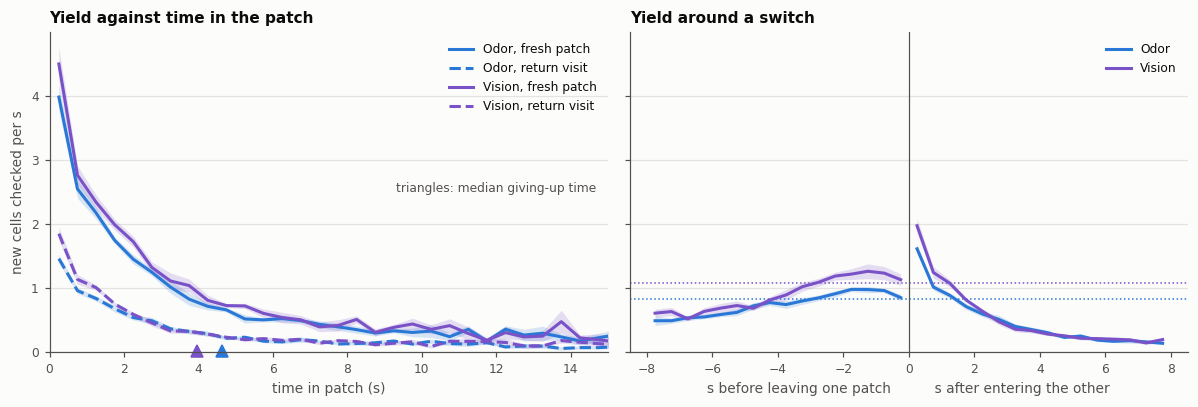

In [6]:
nc = v[~v.cue].copy()
nc['next_new_cell_s'] = nc.groupby(KEYS).new_cell_s.shift(-1)
nc['next_residence_s'] = nc.groupby(KEYS).residence_s.shift(-1)
nc['fresh'] = nc.cells_before == 0
timed = nc[nc.timed]
switches = timed[timed.switched]
W_EDGES = np.arange(0, 8.01, 0.5)

def new_cell_rate(d, edges=T_EDGES):
    return hazard(d.residence_s, None, edges, marks=list(d.new_cell_s))

def rate_before_leaving(d, edges=W_EDGES):      # time counted back from the last frame in the patch
    return hazard(d.residence_s, None, edges, marks=[r - m for r, m in zip(d.residence_s, d.new_cell_s)])

def rate_after_arriving(d, edges=W_EDGES):      # the visit that follows the switch
    return hazard(d.next_residence_s, None, edges, marks=list(d.next_new_cell_s))

def long_run_rate(d):                           # new cells per second of search, over whole trials
    trials = d.groupby(KEYS).agg(cells=('cells_new', 'sum'), search_s=('search_s', 'first'))
    return trials.cells.sum() / trials.search_s.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax = axes[0]
for st in SESSION_TYPES:
    d = timed[timed.session_type == st]
    band(ax, centers(T_EDGES), mouse_curves(d[d.fresh], new_cell_rate), TYPE_COLOR[st], f'{TYPE_LABEL[st]}, fresh patch')
    band(ax, centers(T_EDGES), mouse_curves(d[~d.fresh], new_cell_rate), TYPE_COLOR[st], f'{TYPE_LABEL[st]}, return visit', ls='--')
    ax.plot([give_up[give_up.session_type == st].residence_s.median()], [0.02], '^', color=TYPE_COLOR[st], ms=8, clip_on=False)
ax.set(xlabel='time in patch (s)', ylabel='new cells checked per s', title='Yield against time in the patch', xlim=(0, 15), ylim=(0, None))
ax.text(0.98, 0.5, 'triangles: median giving-up time', transform=ax.transAxes, ha='right', fontsize=8, color=MUTED)
ax.legend()

ax = axes[1]
for st in SESSION_TYPES:
    d = switches[switches.session_type == st]
    band(ax, -centers(W_EDGES), mouse_curves(d, rate_before_leaving), TYPE_COLOR[st], TYPE_LABEL[st])
    band(ax, centers(W_EDGES), mouse_curves(d, rate_after_arriving), TYPE_COLOR[st])
    ax.axhline(long_run_rate(nc[nc.session_type == st]), color=TYPE_COLOR[st], lw=1, ls=':')
ax.axvline(0, color=MUTED, lw=0.8)
ax.set(xlabel='s before leaving one patch          s after entering the other', title='Yield around a switch')
ax.legend()
for ax in axes:
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [7]:
def window(curve_fn, lo, hi):
    """Per-mouse mean rate between lo and hi seconds, from a rate curve on W_EDGES."""
    keep = (W_EDGES[:-1] >= lo) & (W_EDGES[1:] <= hi)
    return lambda d: mouse_curves(d, curve_fn).loc[:, keep].mean(axis=1)

rows = {}
for st in SESSION_TYPES:
    d = switches[switches.session_type == st]
    per_mouse_rates = pd.DataFrame({
        'long-run average': pd.Series({m: long_run_rate(g) for m, g in nc[nc.session_type == st].groupby('mouse')}),
        '4-8 s before leaving': window(rate_before_leaving, 4, 8)(d),
        'last 2 s before leaving': window(rate_before_leaving, 0, 2)(d),
        'first 2 s after arriving': window(rate_after_arriving, 0, 2)(d),
        '2-6 s after arriving': window(rate_after_arriving, 2, 6)(d)})
    last = per_mouse_rates['last 2 s before leaving'] - per_mouse_rates['long-run average']
    d, avg = timed[timed.session_type == st], long_run_rate(nc[nc.session_type == st])
    falls_at = lambda g: centers(T_EDGES)[np.argmax(new_cell_rate(g) < avg)]       # first half-second bin below the average
    rows[st] = {'fresh patch falls to average at (s)': falls_at(d[d.fresh]), 'return visit falls to average at (s)': falls_at(d[~d.fresh]),
                'median giving-up time (s)': give_up[give_up.session_type == st].residence_s.median(),
                **per_mouse_rates.mean(), 'last 2 s minus average': last.mean(), 'p': sps.ttest_1samp(last, 0).pvalue,
                'mice above average': f'{int((last > 0).sum())}/{len(last)}'}
pd.DataFrame(rows).T

,fresh patch falls to average at (s),return visit falls to average at (s),median giving-up time (s),long-run average,4-8 s before leaving,last 2 s before leaving,first 2 s after arriving,2-6 s after arriving,last 2 s minus average,p,mice above average
x,4.25,1.75,4.633,0.829,0.597,0.943,1.057,0.354,0.113,0.04,7/9
v,3.75,1.25,3.949,1.084,0.664,1.211,1.276,0.347,0.127,0.118,5/9


**Returns do diminish, steeply.** A fresh patch yields about 4 new cells per second at first and about 1 per second by 4 s. A return visit starts at 1.5-1.9 per second and is below 0.5 within 3 s.

**On a fresh patch the timing is about what MVT asks for.** Yield from a fresh patch falls to the long-run average at 4.25 s in `x` and 3.75 s in `v`; the median giving-up times are 4.6 and 3.9 s.

**But the leaving is not triggered by low yield.**
- A return visit falls to the long-run average within 1.25-1.75 s, yet section 4 shows mice stay just as long on return visits.
- Yield is at its lowest 4-8 s *before* a mouse leaves (0.60 new cells per s in `x`, 0.66 in `v`, against averages of 0.83 and 1.08). In the last 2 s it is back up to or above the average (0.94 and 1.21; above average in 7/9 and 5/9 mice). The run back out of the patch passes through unchecked cells, so mice are leaving while yield is rising, not when it bottoms out.
- The switch buys about 2 s of above-average yield (1.06 and 1.28 per s), then 0.35 per s for the rest of the next visit.

## 4. Does what the patch has left to offer change how long mice stay?

**Depletion.** When a mouse comes back to a patch, some of its 12 cells have already been checked on this trial. MVT says the more that have, the shorter it should stay. Give-up visits on no-cue trials, split by how many cells were already checked on entry.

**Memory for what has been checked.** On a return visit, what fraction of the cells the mouse goes through are new? If it paid no attention to where it had already been, that fraction would equal the fraction of the patch still unchecked. A mouse that avoided checked cells would beat that.

In [8]:
BEFORE_BINS = pd.IntervalIndex.from_tuples([(-1, 0), (0, 4), (4, 8), (8, 12)])
BEFORE_LABELS = ['0\n(fresh)', '1-4', '5-8', '9-12']
returns = timed[~timed.fresh & (timed.cells_entered > 0)]

CELL_COUNTS = ['cells_new', 'cells_entered', 'cells_before']

def new_fraction(d):
    """Share of the cells entered on return visits that were new, observed and expected with no memory."""
    return pd.Series({'observed': d.cells_new.sum() / d.cells_entered.sum(),
                      'no memory': ((PATCH_CELLS - d.cells_before) / PATCH_CELLS * d.cells_entered).sum() / d.cells_entered.sum()})

rows = {}
for st in SESSION_TYPES:
    d = give_up[give_up.session_type == st]
    rho = d.groupby('mouse')[['cells_before', 'residence_s']].apply(lambda g: sps.spearmanr(g.cells_before, g.residence_s)[0])
    frac = returns[returns.session_type == st].groupby('mouse')[CELL_COUNTS].apply(new_fraction)
    diff = frac.observed - frac['no memory']
    rows[st] = {'giving-up time, fresh (s)': d[d.cells_before == 0].groupby('mouse').residence_s.median().mean(),
                '9-12 cells checked (s)': d[d.cells_before >= 9].groupby('mouse').residence_s.median().mean(),
                'Spearman, time vs cells checked': rho.mean(), 'p (rho)': sps.ttest_1samp(rho, 0).pvalue,
                'mice with rho < 0': f'{int((rho < 0).sum())}/{len(rho)}',
                'new fraction, observed': frac.observed.mean(), 'no memory': frac['no memory'].mean(),
                'difference': diff.mean(), 'p (difference)': sps.ttest_1samp(diff, 0).pvalue}
pd.DataFrame(rows).T

,"giving-up time, fresh (s)",9-12 cells checked (s),"Spearman, time vs cells checked",p (rho),mice with rho < 0,"new fraction, observed",no memory,difference,p (difference)
x,4.445,4.815,0.047,0.031,2/9,0.405,0.409,-0.004,0.112
v,3.776,4.736,0.143,0.0,0/9,0.408,0.4,0.008,0.032


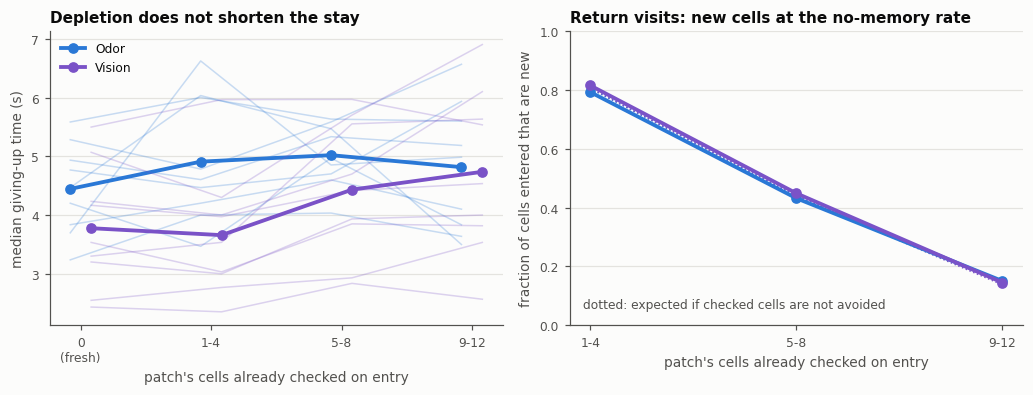

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7))
ax = axes[0]
for i, st in enumerate(SESSION_TYPES):
    d = give_up[give_up.session_type == st]
    med = d.groupby(['mouse', pd.cut(d.cells_before, BEFORE_BINS)], observed=False).residence_s.median().unstack()
    x = np.arange(len(BEFORE_BINS)) + (i - 0.5) * 0.16
    for m in med.index:
        ax.plot(x, med.loc[m], color=TYPE_COLOR[st], lw=1, alpha=0.25)
    ax.plot(x, med.mean(), color=TYPE_COLOR[st], lw=2.5, marker='o', ms=6, label=TYPE_LABEL[st])
ax.set(xticks=range(len(BEFORE_BINS)), xticklabels=BEFORE_LABELS, xlabel="patch's cells already checked on entry",
       ylabel='median giving-up time (s)', title='Depletion does not shorten the stay')
ax.legend(); ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

ax = axes[1]
for st in SESSION_TYPES:
    d = returns[returns.session_type == st]
    frac = d.groupby(['mouse', pd.cut(d.cells_before, BEFORE_BINS[1:])], observed=False)[CELL_COUNTS].apply(new_fraction).unstack()
    ax.plot(range(3), frac['no memory'].mean(), color=TYPE_COLOR[st], lw=1, ls=':')
    ax.errorbar(range(3), frac.observed.mean(), yerr=frac.observed.sem(), color=TYPE_COLOR[st], lw=2.5, marker='o', ms=6, label=TYPE_LABEL[st])
ax.set(xticks=range(3), xticklabels=BEFORE_LABELS[1:], xlabel="patch's cells already checked on entry", ylim=(0, 1),
       ylabel='fraction of cells entered that are new', title='Return visits: new cells at the no-memory rate')
ax.text(0.03, 0.06, 'dotted: expected if checked cells are not avoided', transform=ax.transAxes, fontsize=8, color=MUTED)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Richness.** On a cue trial the two ends are as unequal as patches can be: the target is certainly at the cued end and certainly not at the other. Two comparisons, each holding the truth about the patch fixed so that only the cue differs:

- *Empty patch:* giving-up time at the uncued end of a cue trial, against the empty end of a no-cue trial. MVT (and any use of the cue) says leave the uncued end sooner.
- *Patch with the target:* time before leaving the cued end, against the target's end on a no-cue trial. Most of these visits end in a find, so the median is a Kaplan-Meier estimate with finds as censoring; it is biased long, but equally in both conditions. MVT says stay longer at the cued end.

In [10]:
vt = v[v.timed]
empty = vt[~vt.target_here].groupby(['session_type', 'mouse', 'cue_here']).residence_s.median().unstack()
holds = (vt[vt.target_here].groupby(['session_type', 'mouse', 'cue_here'])[['residence_s', 'switched']]
         .apply(lambda g: km_median(g.residence_s, g.switched)).unstack())
RICHNESS = {'empty patch: uncued end minus no-cue (s)': (empty, 'uncued end'),
            "target's patch: cued end minus no-cue (s)": (holds, 'cued end')}

def across_mice(diff):
    lo, hi = sps.t.interval(0.95, len(diff) - 1, diff.mean(), sps.sem(diff))
    return {'difference': diff.mean(), 'ci_lo': lo, 'ci_hi': hi, 'p': sps.ttest_1samp(diff, 0).pvalue}

rows = {}
for name, (table, cued) in RICHNESS.items():
    for st in SESSION_TYPES:
        d = table.loc[st].dropna(subset=[cued, 'no cue'])
        diff = d[cued] - d['no cue']
        rows[(name, st)] = {'no cue (s)': d['no cue'].mean(), 'cue trial (s)': d[cued].mean(), **across_mice(diff),
                            'mice shorter with cue': f'{int((diff < 0).sum())}/{len(diff)}'}
richness = pd.DataFrame(rows).T
richness

no cue (s) cue trial (s) difference  ci_lo  ci_hi      p mice shorter with cue
empty patch: uncued end minus no-cue (s)  x      4.638         4.319     -0.319  -0.62 -0.017  0.041                   7/9
                                          v      4.054         3.904      -0.15 -0.301  0.001  0.051                   7/9
target's patch: cued end minus no-cue (s) x      5.971         6.001       0.03 -0.637  0.697   0.92                   6/9
                                          v       5.59         5.423     -0.168 -0.854  0.519  0.589                   6/9

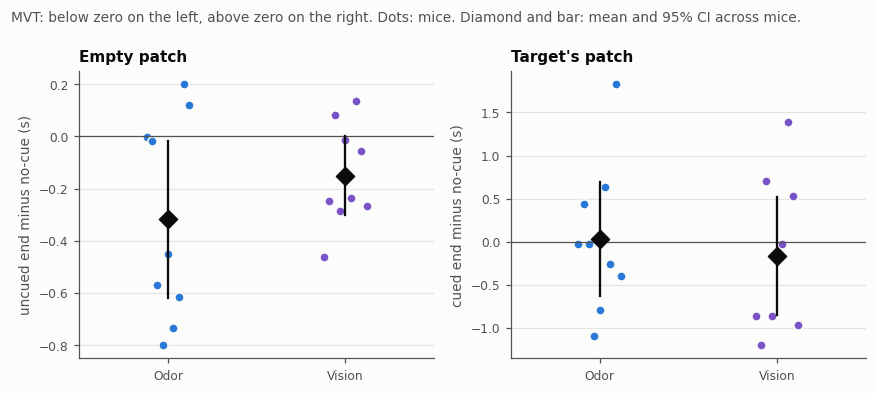

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, (name, (table, cued)) in zip(axes, RICHNESS.items()):
    for i, st in enumerate(SESSION_TYPES):
        d = table.loc[st].dropna(subset=[cued, 'no cue'])
        diff = d[cued] - d['no cue']
        ax.scatter(i + np.linspace(-0.12, 0.12, len(diff)), diff, s=36, color=TYPE_COLOR[st], edgecolor='#fcfcfb', lw=1, zorder=2)
        r = richness.loc[(name, st)]
        ax.plot([i, i], [r.ci_lo, r.ci_hi], color=INK, lw=1.5, zorder=3)
        ax.scatter([i], [r.difference], s=70, color=INK, marker='D', zorder=4)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=range(len(SESSION_TYPES)), xticklabels=[TYPE_LABEL[s] for s in SESSION_TYPES], xlim=(-0.5, len(SESSION_TYPES) - 0.5),
           title=name.split(':')[0].capitalize(), ylabel=name.split(': ')[1])
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
fig.suptitle('MVT: below zero on the left, above zero on the right. Dots: mice. Diamond and bar: mean and 95% CI across mice.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

## Summary

**There is a typical persistence period, and it is one lap.** A mouse that enters an end runs to the far wall and back, which takes about 4 s (median giving-up time 4.6 s in odor `x` sessions, 3.9 s in vision `v`), and only then becomes likely to leave. After that first lap the chance of leaving is roughly constant at 0.11-0.13 per second.

**Does it follow the marginal value theorem? Only in the sense that the lap is about the right length for a fresh patch.**

| MVT prediction | Result |
|---|---|
| Returns diminish with time in the patch | Yes. Yield falls from about 4 new cells per s to about 1 within 4 s. |
| Leave when yield has fallen to the long-run average | Matches for a fresh patch (yield reaches the average at 3.75-4.25 s). Fails for return visits, which reach it within 2 s without the stay getting shorter. Yield is rising, not falling, in the seconds before a mouse leaves. |
| Shorter stay in a depleted patch | No. Mice stay slightly *longer* in a patch with 9-12 cells already checked than in a fresh one (4.4 to 4.8 s in `x`, 3.8 to 4.7 s in `v`; 7/9 and 9/9 mice). |
| Longer stay in a richer patch | Barely. Mice leave the uncued, empty end sooner than an empty end on a no-cue trial by 0.3 s in `x` sessions (p = 0.04, 7/9 mice) and 0.15 s in `v` (p = 0.05, 7/9 mice). They do not stay longer at the cued end in either. |
| Longer stay when travel is longer | Not testable; the crossing takes well under a second. |

**Mice do not keep track of what they have checked.** A fresh visit checks a median of 8-9 of the patch's 12 cells and all 12 on only 5-6% of visits. On coming back, the share of cells entered that are new (41%) equals what it would be if the mouse ignored where it had already been (40-41%). A patch is left with cells unchecked and those cells are not sought out on return.

**Reading the results.**
- The simplest description is a fixed routine - run a lap of this end, then leave at a constant rate - rather than a decision that weighs what the patch still has to offer. It is not a bad routine: one lap is about when a fresh patch stops paying. But it is not adjusted when the patch is already depleted, and adjusted only slightly by the cue.
- This fits the earlier notebooks. Leaving the correct end on more than 40% of trials is what a lap-then-leave routine produces when one lap covers two thirds of the cells.
- Time and distance cannot be separated here: a lap takes about the same time on every visit, so a rule based on either would look the same.
- "Depleted" patches are, by construction, visited later in a trial than fresh ones. A mouse that slows down or lingers more as a search drags on would look like one staying longer in depleted patches. The data rule out *shorter* stays, which is the MVT prediction, but not that confound.
- The yield measure assumes a cell is checked when the nose enters it, which is the task's own rule; what the mouse treats as checked is unknown.
- p-values are unadjusted.
- Excluded: the odor `o` and `t` shaping sessions, sessions beyond each mouse's ten, trials with the target in the middle row, searches over 120 s, entries less than one cell deep, and - from everything timed - the 32% of visits already under way when the trial started.